# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)
print("shape:", patients.shape)
display(patients.dtypes)

exploratory_chart = alt.Chart(patients).mark_point(filled=True, size=90).encode(
    x=alt.X("sessions_attended:Q", title="Sessions attended (of 36)"),
    y=alt.Y("walk_distance_m:Q", title="Six-minute walk distance (m)", scale=alt.Scale(zero=False)),
    color=alt.Color("program:N", title="Program"),
    shape=alt.Shape("program:N", title="Program"),
    tooltip=["patient_id:N", "program:N", "sessions_attended:Q", "walk_distance_m:Q"],
).properties(title="Six-minute walk distance and sessions attended, by program")

exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

shape: (12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

The chart explores whether patients who attend more rehab sessions walk farther in the six-minute walk test at discharge, and whether that looks different in the two programs. Each point is one patient: the sessions they attended (out of 36) against how far they walked in six minutes at discharge, in meters, with color and shape marking their program. In both programs the points rise from lower left to upper right: patients who attended more sessions walked farther, from 352 m at 10 sessions to 458 m at 34. These are only twelve patients who chose their own program, so the chart cannot show that attending more sessions causes a longer walk; patients who were fitter to begin with may simply have attended more, and twelve points are too few to rule out chance.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


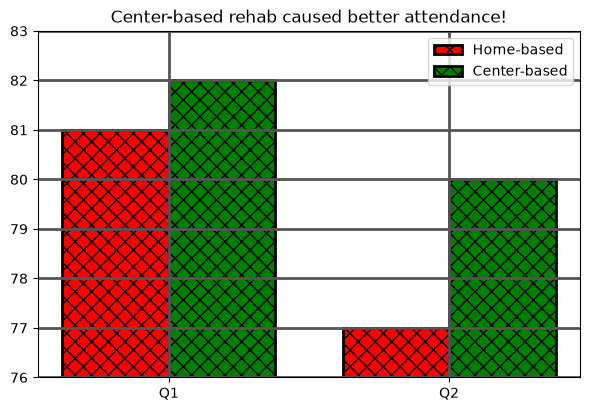

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim",
     "problem": "The title says center-based rehab caused better attendance, but patients chose their program, so the bars can only show that center-based attendance was higher, not why; in Q1 the two programs were 1 point apart.",
     "repair": "Use a descriptive title that states what the bars show without a cause: attendance fell from Q1 to Q2 in both programs, more in the home-based one."},
    {"category": "truncated baseline",
     "problem": "The y-axis starts at 76%, so in Q2 the center-based bar (80%) is drawn four times as tall as the home-based bar (77%) even though the gap is only 3 points.",
     "repair": "Start the y-axis at zero with set_ylim(0, 100), so each bar's length is proportional to its value."},
    {"category": "missing unit",
     "problem": "The y-axis has no label, so readers cannot tell that the numbers are the percentage of scheduled sessions patients attended.",
     "repair": "Label the y-axis Scheduled sessions attended (%), label the x-axis Quarter, and write each value on its bar."},
    {"category": "color-only encoding",
     "problem": "Only red versus green tells the programs apart, a pair many colorblind readers cannot distinguish and one that disappears in grayscale, because every bar has the same hatch.",
     "repair": "Use colorblind-safe orange and blue and give each program its own hatch: dots for home-based and stripes for center-based."},
    {"category": "distracting decoration",
     "problem": "Thick black edges, a heavy dark grid, and the same cross-hatch on every bar carry no data and pull attention away from the bar heights.",
     "repair": "Drop the thick edges and the grid, hide the top and right spines, and keep hatches only where they mark the program."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title says center-based rehab caused better attendance, but patients chose their program, so the bars can only show that center-based attendance was higher, not why; in Q1 the two programs were 1 point apart.
    repair: Use a descriptive title that states what the bars show without a cause: attendance fell from Q1 to Q2 in both programs, more in the home-based one.
truncated baseline: The y-axis starts at 76%, so in Q2 the center-based bar (80%) is drawn four times as tall as the home-based bar (77%) even though the gap is only 3 points.
    repair: Start the y-axis at zero with set_ylim(0, 100), so each bar's length is proportional to its value.
missing unit: The y-axis has no label, so readers cannot tell that the numbers are the percentage of scheduled sessions patients attended.
    repair: Label the y-axis Scheduled sessions attended (%), label the x-axis Quarter, and write each value on its bar.
color-only encoding: Only red versus green tells the programs

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

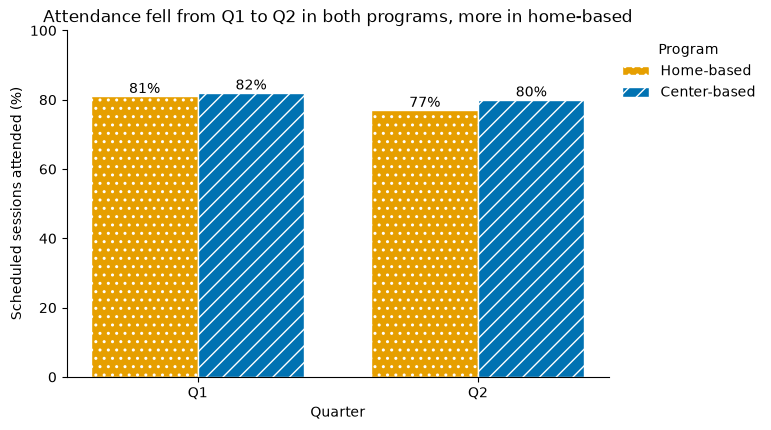

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(x - width / 2, home, width, label="Home-based",
                            color=ORANGE, hatch="..", edgecolor="white")
center_bars = redesign_ax.bar(x + width / 2, center, width, label="Center-based",
                              color=BLUE, hatch="//", edgecolor="white")
redesign_ax.bar_label(home_bars, fmt="%d%%")
redesign_ax.bar_label(center_bars, fmt="%d%%")

redesign_ax.set_xticks(x, quarters)
redesign_ax.set_ylim(0, 100)
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_title("Attendance fell from Q1 to Q2 in both programs, more in home-based")
redesign_ax.spines[["top", "right"]].set_visible(False)
redesign_ax.legend(title="Program", loc="upper left", bbox_to_anchor=(1, 1), frameon=False)

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup)

question = "How did the share of patients meeting the weekly exercise goal change across the four follow-up visits in each program?"
audience = "The rehab program coordinator, who will use it to decide where to add follow-up support."
intended_claim = "Both programs improved from visit 1 to visit 4, and by visit 4 more Center-based patients met the goal than Home-based patients, 79% against 70%."
y_measure = "Percentage of patients seen at the visit who met the weekly goal of 150 minutes of exercise (%)"
grain = "One row of the plotting table and one point on a line is one program at one follow-up visit."
data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[["program", "visit_number", "goal_met_pct"]]

supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

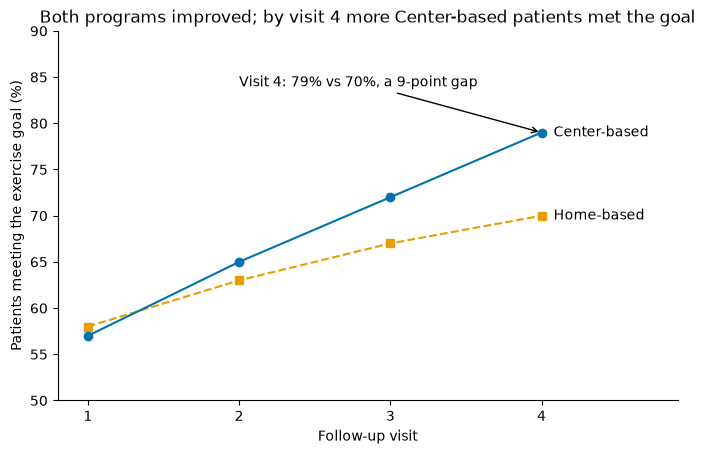

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(home_goals["visit_number"], home_goals["goal_met_pct"],
                    color=ORANGE, marker="s", linestyle="--")
explanatory_ax.plot(center_goals["visit_number"], center_goals["goal_met_pct"],
                    color=BLUE, marker="o", linestyle="-")
explanatory_ax.text(4.08, 70, "Home-based", va="center")
explanatory_ax.text(4.08, 79, "Center-based", va="center")
explanatory_ax.annotate("Visit 4: 79% vs 70%, a 9-point gap", xy=(4, 79), xytext=(2.0, 84),
                        arrowprops=dict(arrowstyle="->"))

explanatory_ax.set(xlabel="Follow-up visit", ylabel="Patients meeting the exercise goal (%)",
                   xlim=(0.8, 4.9), ylim=(50, 90),
                   title="Both programs improved; by visit 4 more Center-based patients met the goal")
explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.spines[["top", "right"]].set_visible(False)

explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = (
    "Line chart of the percentage of patients meeting the weekly goal of 150 minutes of exercise "
    "(y-axis, %) at four follow-up visits (x-axis, visits 1 to 4) for the Home-based and Center-based "
    "rehab programs. Both rise across the visits: Home-based from 58% to 70% and Center-based from 57% "
    "to 79%, so the programs start about equal and Center-based finishes 9 points higher at visit 4, "
    "79% against 70%. Patients chose their program, so the gap does not show that center-based rehab "
    "causes more exercise, and each percentage covers only the patients seen at that visit, about 45 "
    "per program, so a 9-point gap could also come from chance or from who returned."
)

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

1. Home-based bars are dotted and Center-based bars are striped, with a legend and values shown on every bar. The other chart uses dashed lines with squares for Home-based and solid lines with circles for Center-based. Both are labeled, so no color is needed.

2. The arrow points to Center-based at visit 4 (4, 79). The text just says the values are 79% vs 70%, a 9-point difference. It doesn't make any claims about why.

3. Nothing is cut off or overlapping. `bbox_inches="tight"` keeps the legend and labels inside the PNGs, and the annotation sits above the lines.

4. Patients chose their own program, and each percentage is based on only about 45 patients. So we can't say the program caused the difference or rule out chance and differences in who returned.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m